# Иерархическая кластеризация. Тюков Даниил

**Данные:** экономические условия в 48 городах мира в 1991 году (отдел экономических исследований банка UBS, Швейцария).

| Переменная | Описание |
|---|---|
| `City` | Название города |
| `Work` | Взвешенное среднее число рабочих часов в год по 12 профессиям |
| `Price` | Индекс цен 112 товаров и услуг, включая аренду жилья |
| `Salary` | Индекс зарплаты за час работы по 12 профессиям после налогов |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score

%matplotlib inline

## 1. Загрузка и очистка данных

In [2]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",")
df_raw.head()

,City,Work,Price,Salary
0,Amsterdam,1714,65.6,49.0
1,Athens,1792,53.8,30.4
2,Bogota,2152,37.9,11.5
3,Bombay,2052,30.3,5.3
4,Brussels,1708,73.8,50.5


In [3]:
df_raw.shape

(48, 4)

In [4]:
print("Пропуски по признакам:")
print(df_raw.isna().sum())
df_raw[df_raw["Work"] < 0]

Пропуски по признакам:
City      0
Work      0
Price     0
Salary    0
dtype: int64


,City,Work,Price,Salary
6,Cairo,-9999,37.1,-9999.0
17,Jakarta,-9999,43.6,-9999.0


У Каира и Джакарты нет данных о рабочих часах и зарплате. Удалим эти два города

In [5]:
df = df_raw[df_raw["Work"] > 0]
cities = df["City"].tolist()
X_raw = df[["Work", "Price", "Salary"]]
X_raw.head()

,Work,Price,Salary
0,1714,65.6,49.0
1,1792,53.8,30.4
2,2152,37.9,11.5
3,2052,30.3,5.3
4,1708,73.8,50.5


## 2. Описательные статистики

In [6]:
X_raw.describe()

,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


### Ящики с усами

Строим отдельный ящик с усами для каждого признака

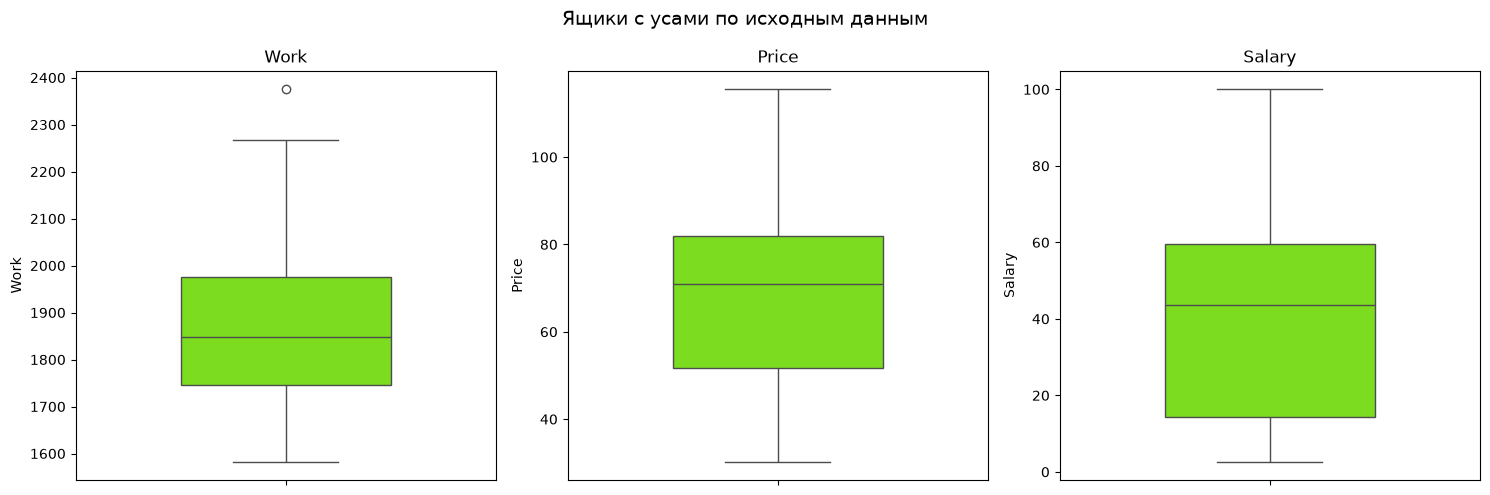

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
features = ["Work", "Price", "Salary"]
for ax, f in zip(axes, features):
    sns.boxplot(y=X_raw[f], ax=ax, color="lawngreen", width=0.5)
    ax.set_title(f)

fig.suptitle("Ящики с усами по исходным данным", fontsize=14)
plt.tight_layout()
plt.show()

In [8]:
df_raw.loc[X_raw["Work"].idxmax()]

City      Hong_Kong
Work           2375
Price          63.8
Salary         27.8
Name: 15, dtype: object

Единственный выброс — **Гонконг** по числу рабочих часов (2375 в год). Остальные значения в порядке

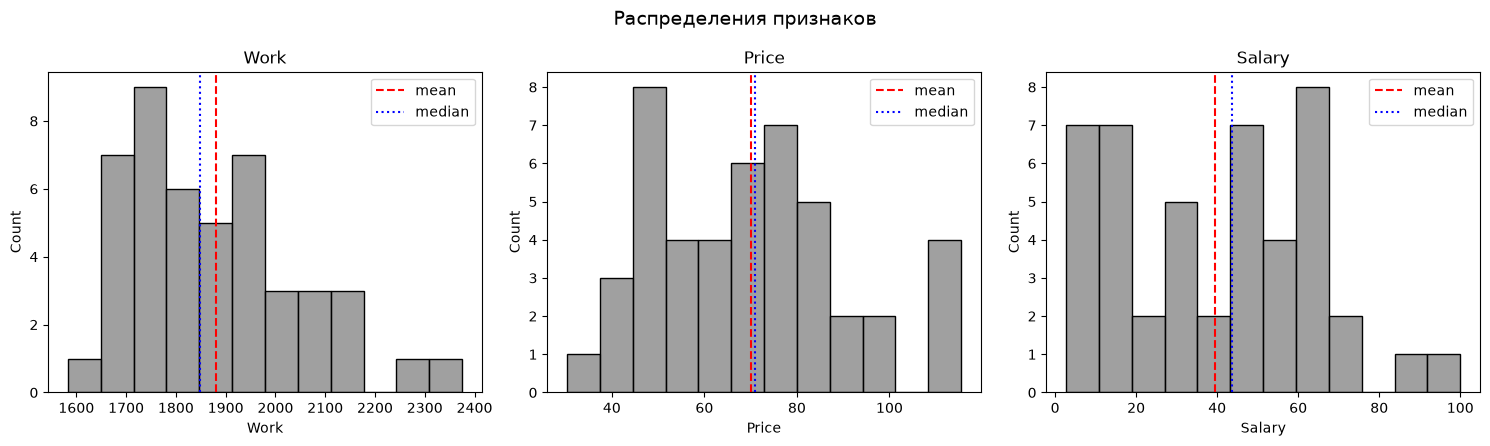

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, f in zip(axes, features):
    sns.histplot(X_raw[f], ax=ax, color="grey", bins=12)
    ax.axvline(X_raw[f].mean(), color="red", ls="--", label="mean")
    ax.axvline(X_raw[f].median(), color="blue", ls=":", label="median")
    ax.set_title(f)
    ax.legend()
fig.suptitle("Распределения признаков", fontsize=14)
plt.tight_layout()
plt.show()

В целом большого перекоса не наблюдается между средним и медианой

### Корреляции

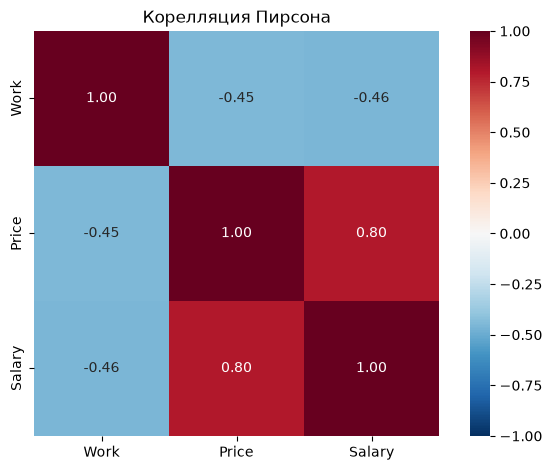

In [10]:
sns.heatmap(X_raw.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Корелляция Пирсона")
plt.tight_layout()
plt.show()

**Наблюдения:**
- Цены и зарплаты сильно связаны: r = 0,80. Где высокие цены, там больше платят.
- Рабочие часы связаны с ними обратно (r = −0,45): где платят меньше, там работают больше по часам.

## Стандартизация

Шкалы признаков сильно различаются. Переводим каждый признак в z-оценки

In [12]:
X = StandardScaler().fit_transform(X_raw)
X_df = pd.DataFrame(X, columns=["Work", "Price", "Salary"])
X_df.head()

,Work,Price,Salary
0,-0.962166,-0.212712,0.386095
1,-0.509827,-0.770489,-0.373488
2,1.577891,-1.522069,-1.145323
3,0.997969,-1.881316,-1.398517
4,-0.996961,0.174896,0.447351


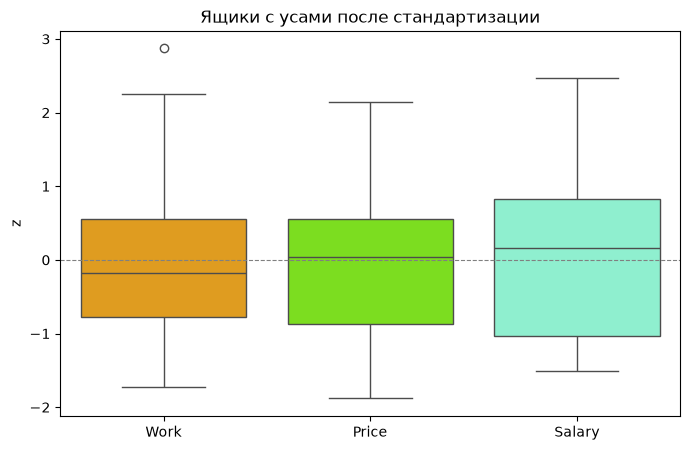

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=X_df, ax=ax, palette=["orange", "lawngreen", "aquamarine"])
ax.axhline(0, color="grey", lw=0.8, ls="--")
ax.set_title("Ящики с усами после стандартизации")
ax.set_ylabel("z")
plt.show()

На одной шкале видно: у Salary самый широкий межквартильный размах, у Work — самый узкий ящик и выброс сверху (Гонконг).

## 2. Иерархическая кластеризация: разные методы связи

Сравниваем четыре метода связи (linkage):

| Метод | Расстояние между кластерами |
|---|---|
| `complete` | Максимальное расстояние между точками разных кластеров |
| `average` |  Среднее расстояние между всеми парами точек из разных кластеров|
| `centroid` | Среднее расстояние между центрами кластеров |
| `ward` | Минимизирует прирост внутрикластерной дисперсии при объединении |

In [14]:
METHODS = ["average", "complete", "centroid", "ward"]
linkages = {m: linkage(X, method=m, metric="euclidean") for m in METHODS}

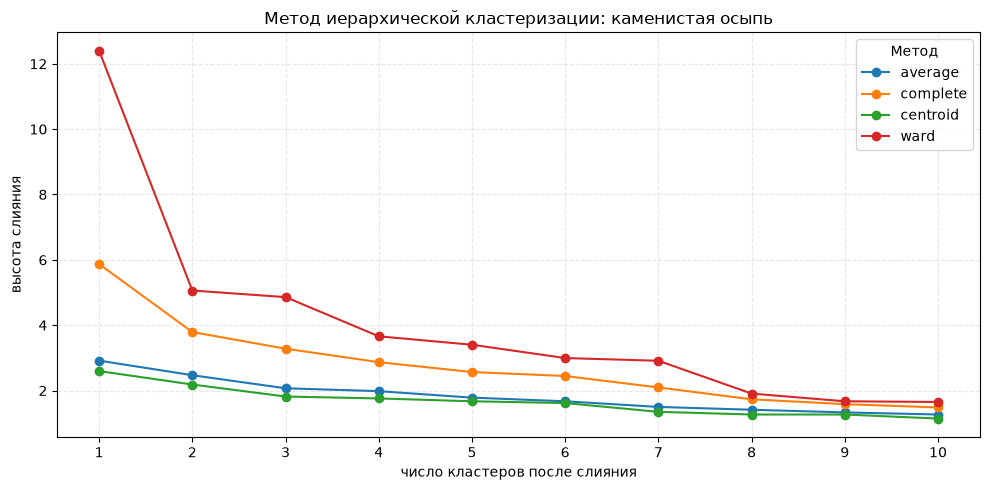

In [15]:
methods_to_plot = ["average", "complete", "centroid", "ward"]

fig, ax = plt.subplots(figsize=(10, 5))

for m in METHODS:
    Z = linkages[m]
    heights = Z[::-1, 2]

    ax.plot(range(1, 11), heights[:10], marker="o", label=m)

ax.set_xticks(range(1, 11))
ax.set_xlabel("число кластеров после слияния")
ax.set_ylabel("высота слияния")
ax.set_title("Метод иерархической кластеризации: каменистая осыпь")
ax.legend(title="Метод")
plt.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()


Скачок, когда 2 кластера, но будет деление "богатые - бедные", что не очень интересно, у всех, кроме Ward скачков резких нет, кроме некого "скачочка" у трёх кластеров у average и centroid, поэтому выберем 4, 
как у некий компромисс

### Дендрограммы

Красная пунктирная линия — разрез на 4 кластера.

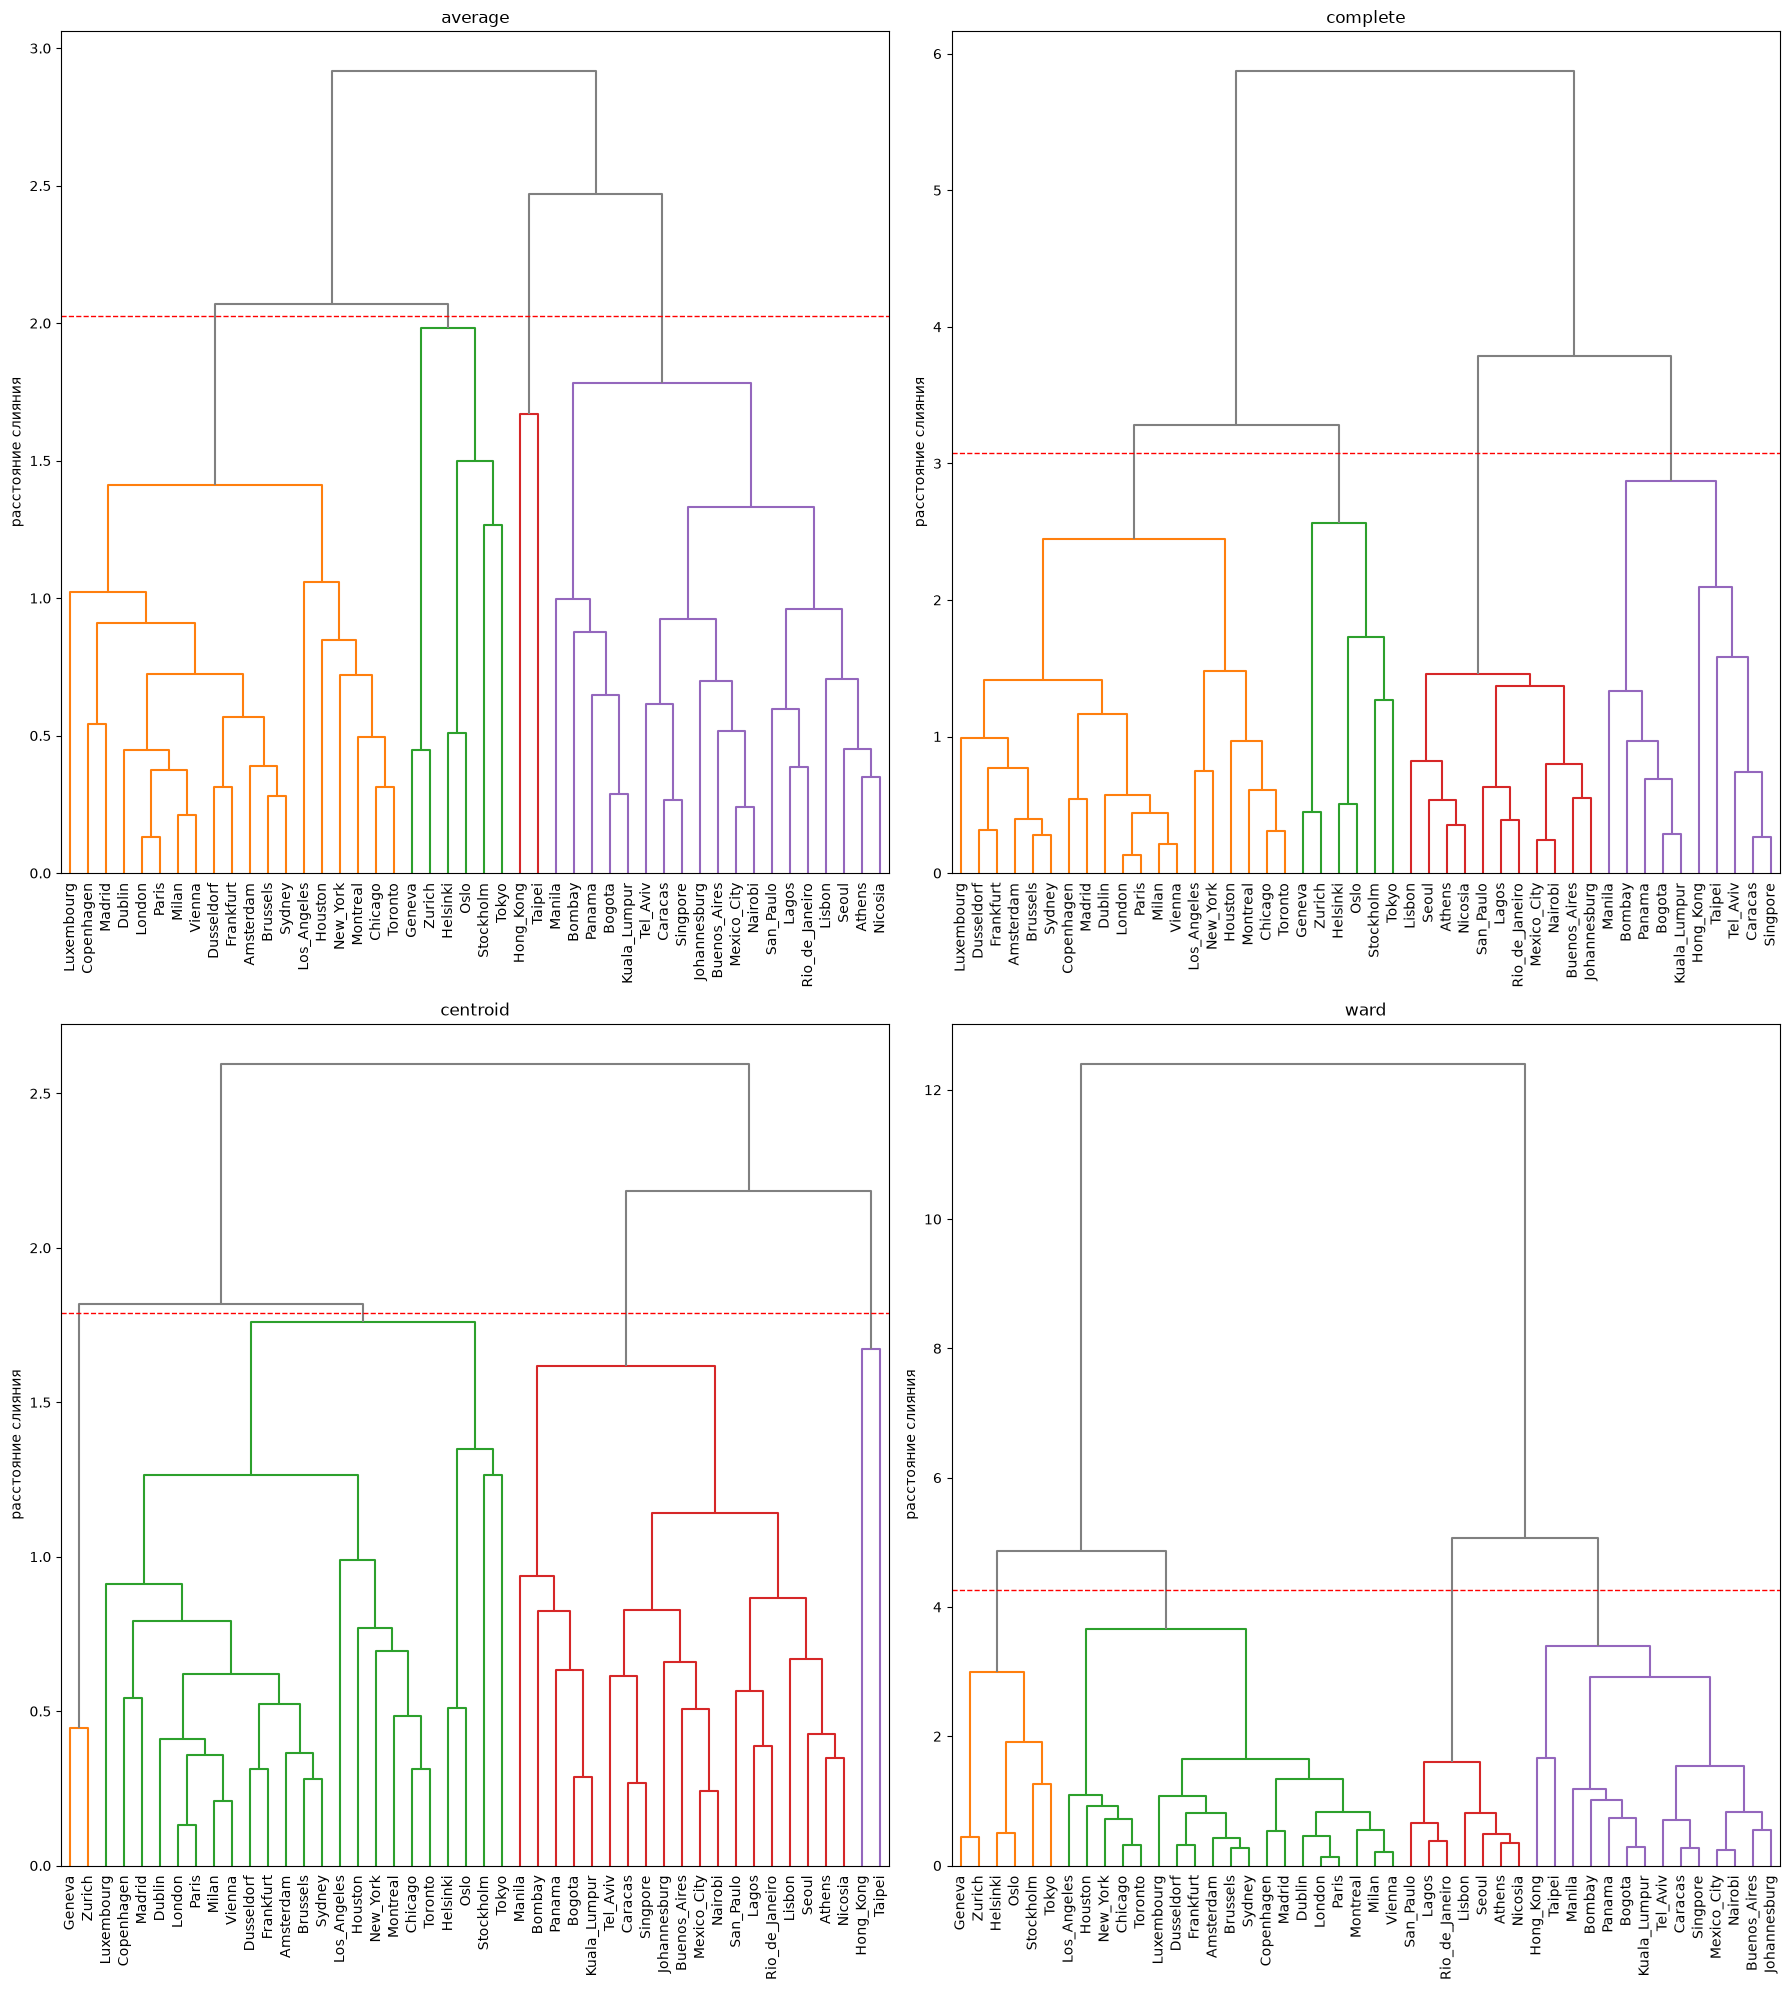

In [16]:
CLUSTERS = 4

def cut_height(Z, k):
    return (Z[-k, 2] + Z[-k + 1, 2]) / 2

def plot_dendrogram(m, ax):
    Z = linkages[m]
    h = cut_height(Z, CLUSTERS)
    dendrogram(Z, labels=cities, ax=ax, leaf_rotation=90, leaf_font_size=10,
               color_threshold=h, above_threshold_color="grey")
    ax.axhline(h, color="red", ls="--", lw=1)
    ax.set_title(m, fontsize=12)
    ax.set_ylabel("расстояние слияния")

fig, axes = plt.subplots(2, 2, figsize=(18, 20))
for ax, m in zip(axes.ravel(), METHODS):
    plot_dendrogram(m, ax)
plt.tight_layout()
plt.show()

**Что видно на дендрограммах:**
- **centroid** и **average** выделяют небольшие группы (например, Гонконг + Тайбэй) и дают менее сбалансированное дерево.
- **complete**, и **ward** дают похожую структуру с несколькими крупными, хорошо различимыми ветвями.

# Метрики Силуэт, индексы Калинского–Харабаза и Дэвиса–Болдина

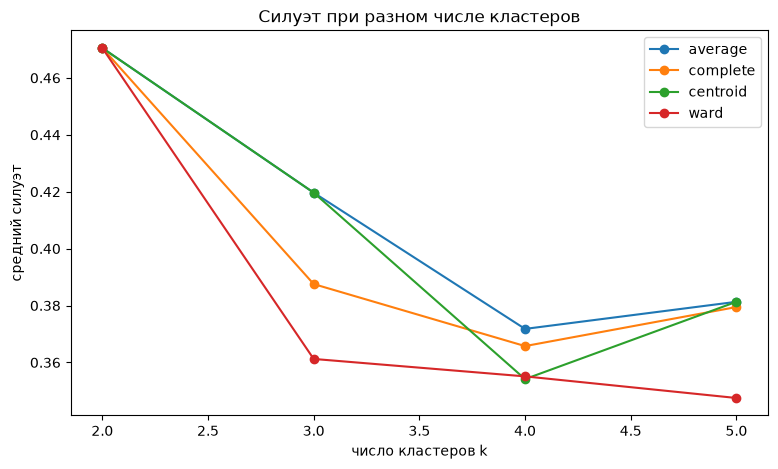

In [17]:
K_RANGE = range(2, 6)
rows, labels_all = [], {}

for m in METHODS:
    Z = linkages[m]
    sil = {k: silhouette_score(X, fcluster(Z, k, criterion="maxclust")) for k in K_RANGE}
    lab = fcluster(Z, CLUSTERS, criterion="maxclust")
    labels_all[m] = lab
    rows.append({
        "method": m,
        **{f"k={k}": sil[k] for k in K_RANGE},
        f"CH (k={CLUSTERS})": calinski_harabasz_score(X, lab),
        f"DB (k={CLUSTERS})": davies_bouldin_score(X, lab),
        f"размеры (k={CLUSTERS})": "/".join(map(str, sorted(np.bincount(lab)[1:], reverse=True))),
    })

summary = pd.DataFrame(rows).set_index("method")
summary.round(3)

fig, ax = plt.subplots(figsize=(9, 5))
for m in METHODS:
    ax.plot(list(K_RANGE), [summary.loc[m, f"k={k}"] for k in K_RANGE],
            marker="o", label=m)
ax.set_xlabel("число кластеров k")
ax.set_ylabel("средний силуэт")
ax.set_title("Силуэт при разном числе кластеров")
ax.legend()
plt.show()

In [18]:
summary

,k=2,k=3,k=4,k=5,CH (k=4),DB (k=4),размеры (k=4)
method,,,,,,,
average,0.470499,0.419660,0.371789,0.381313,33.494228,0.965561,19/19/6/2
complete,0.470499,0.387546,0.365753,0.379474,40.341690,1.062935,19/11/10/6
centroid,0.470499,0.419660,0.354155,0.381313,27.625362,0.751180,23/19/2/2
ward,0.470499,0.361234,0.355110,0.347512,38.929987,1.002428,19/14/7/6


По силуэту явно лучше average, по индексу Дэвиса–Болдина centroid (на втором месте average), по индексу Калински-Харабаша complete. 

## Профили кластеров

In [19]:
df["cluster"] = labels_all["average"]

profile = df.groupby("cluster")[features].mean()
profile.insert(0, "n", df.groupby("cluster").size())
profile.round(2)

,n,Work,Price,Salary
cluster,,,,
1,19,1792.00,77.53,55.16
2,6,1780.50,108.55,71.30
3,2,2260.00,74.05,31.15
4,19,1959.21,50.12,14.79


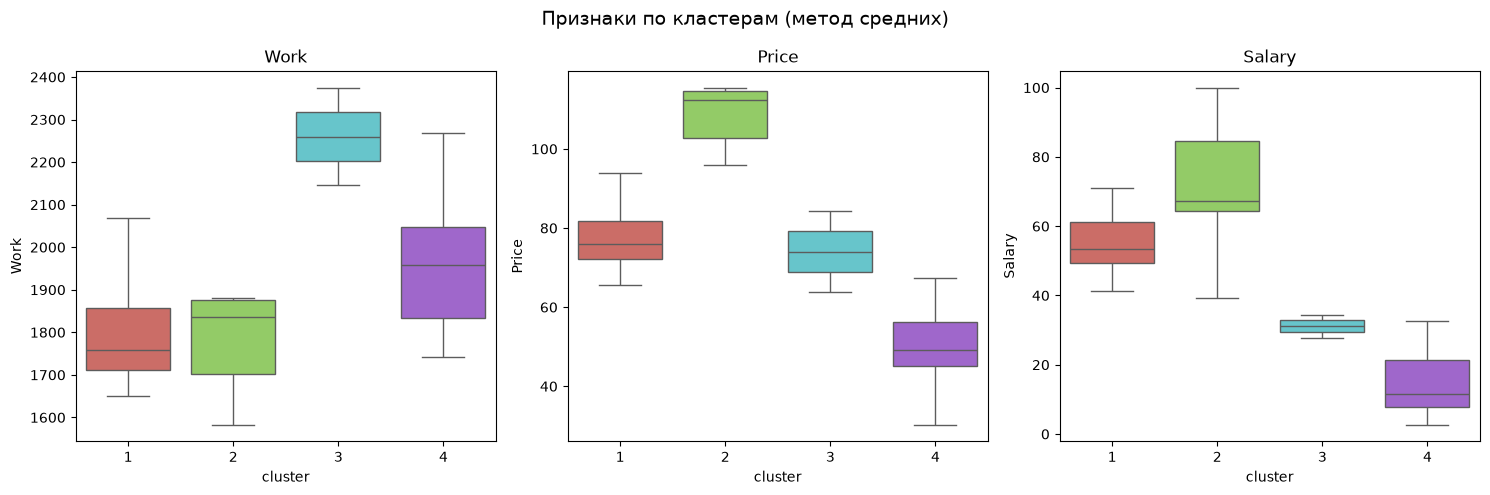

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
pal = sns.color_palette("hls", CLUSTERS)
for ax, f in zip(axes, features):
    sns.boxplot(data=df, x="cluster", y=f, hue="cluster", palette=pal, legend=False, ax=ax)
    ax.set_title(f)
fig.suptitle("Признаки по кластерам (метод cредних)", fontsize=14)
plt.tight_layout()
plt.show()

Видно, что кластеры имеют какую-то разделенность <br>
1 кластер: не так много рабочих часов, но цены и зарплаты на примерно одном уровне (Европа, Австралия и Северная Америка) <br>
2 кластер: самые высокие цены, зарплаты также на уровне, хотя медиана ниже (Европа и Токио) <br>
3 кластер: много работают, больше всех, но зарплаты чуть лучше  4 кластера и цены на уровне 1 кластера (Китай) <br>
4 кластер: страны с низкой зарплатой и низкими ценами (Страны Азии, Африки, Латинской америки)

In [21]:
for c, grp in df.groupby("cluster"):
    print(f"{c}: " + ", ".join(grp["City"]))

1: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna
2: Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich
3: Hong_Kong, Taipei
4: Athens, Bogota, Bombay, Buenos_Aires, Caracas, Johannesburg, Kuala_Lumpur, Lagos, Lisbon, Manila, Mexico_City, Nairobi, Nicosia, Panama, Rio_de_Janeiro, San_Paulo, Seoul, Singpore, Tel_Aviv


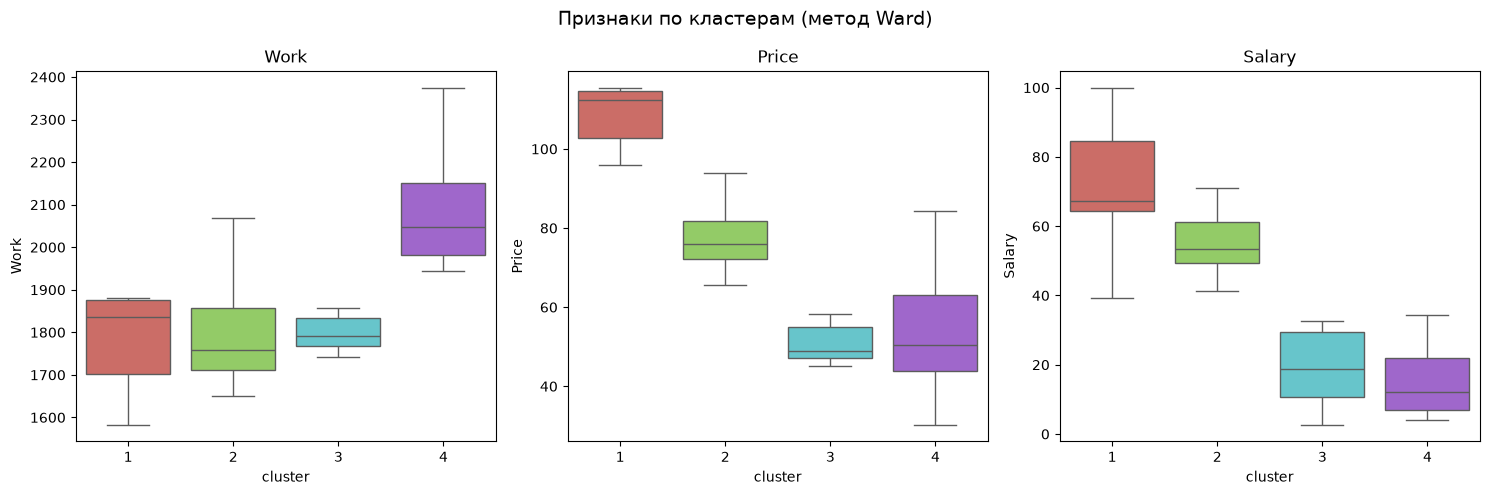

1: Geneva, Helsinki, Oslo, Stockholm, Tokyo, Zurich
2: Amsterdam, Brussels, Chicago, Copenhagen, Dublin, Dusseldorf, Frankfurt, Houston, London, Los_Angeles, Luxembourg, Madrid, Milan, Montreal, New_York, Paris, Sydney, Toronto, Vienna
3: Athens, Lagos, Lisbon, Nicosia, Rio_de_Janeiro, San_Paulo, Seoul
4: Bogota, Bombay, Buenos_Aires, Caracas, Hong_Kong, Johannesburg, Kuala_Lumpur, Manila, Mexico_City, Nairobi, Panama, Singpore, Taipei, Tel_Aviv


In [25]:
df["cluster"] = labels_all["ward"]

profile = df.groupby("cluster")[features].mean()
profile.insert(0, "n", df.groupby("cluster").size())
profile.round(2)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
pal = sns.color_palette("hls", CLUSTERS)
for ax, f in zip(axes, features):
    sns.boxplot(data=df, x="cluster", y=f, hue="cluster", palette=pal, legend=False, ax=ax)
    ax.set_title(f)
fig.suptitle("Признаки по кластерам (метод Ward)", fontsize=14)
plt.tight_layout()
plt.show()
for c, grp in df.groupby("cluster"):
    print(f"{c}: " + ", ".join(grp["City"]))

Хоть часто основной метод Ward, но тут прям явного деления, как в предыдущем случае не увидел, хотя тут также есть упорядочивание по ценам, зарплатам, и обратное по рабочим часам, но на мой взгляд предыдущий результат не хуже